In [17]:
import math
import numpy as np
import tensorflow as tf

from plotly.subplots import make_subplots
import plotly.graph_objects as go

from tf_ofcs.components import *
from tf_ofcs.datatypes import ElectricalSignal, OpticalSignal, TensorCompatible
from tf_ofcs.utils import dbm_to_w, from_db, to_tensor, pam_constellation, symbol_mapping_to_gray
from tf_ofcs.plot import *

from typing import Optional

In [169]:
Component.trace_debug_enabled_by_default = False

class PAMSystem(Composition):
    def __init__(self, name: Optional[str] = None) -> None:
        super().__init__([], name=name)

        self.rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
        self.lpf = BandPassFilter(min_frequency=[0.0], max_frequency=[10e9], name="lpf")
        self.laser = Laser(power=[1e-3], name="laser")
        self.photodiode = Photodiode()
        self.rx_filter = FIRFilter(taps=[[0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0]], name="rx_filter")
        self.slice_signal = SliceSignal(start=3, end=-3)
        self.downsampler = Downsample(10)
        self.bitseq_generator = BitSequenceGenerator(length=512, rng=self.rng)

        self.filter_initialized = tf.Variable(False)

        self.channel = Composition([
            OpticalAWGN(relative_db=[-30.0], rng=self.rng, name="channel_noise"),
            OpticalFiber(
                attenuation=[0.22],
                length=[40.0],
                chromatic_dispersion=[17.0],
                eff_non_linear_coeff=[1.76],
                central_frequency=193.414e12,
                step_count=1,
                enable_nonlinear_effects=False,
                name="fiber"
            )
        ], name="channel")

        self.encoder = PAMEncoder(
            sampling_rate=100e9,
            data_rate=10e9,
            symbol_encoder=PAMSymbolEncoder(
                bits_per_symbol=1,
                adjust_for_mzm=True,
                name="pam_symbol_encoder"
            ),
            name="encoder"
        )

        self.decoder = PAMDecoder(
            data_rate=10e9,
            symbol_decoder=PAMSymbolDecoder(
                bits_per_symbol=1,
                name="pam_symbol_decoder"
            ),
            name="decoder"
        )

        self.transmitter = Composition([
            self.lpf,
            Fork(shape=[2]),
            MapComponents([self.laser, Identity()]),
            MachZehnderModulator(name="modulator")
        ], name="transmitter")

        self.receiver = Composition([
            self.lpf,
            self.photodiode,
            self.downsampler,
            Identity(name="before_filter"),
            self.rx_filter,
            self.slice_signal,
        ], name="receiver")

        self.components = [
            self.encoder,
            self.transmitter,
            self.channel,
            self.receiver,
            self.decoder
        ]

        self.test_sequence_generator = Composition([
            self.bitseq_generator,
            self.encoder,
            Fork([2]),
            MapComponents([
                Composition([
                    self.transmitter,
                    self.channel,
                    self.photodiode,
                    self.lpf,
                    self.downsampler
                ]),
                Composition([
                    self.lpf,
                    self.downsampler,
                    Lambda(
                        lambda signal: ElectricalSignal(
                            samples=tf.square(tf.math.cos(math.pi * signal.samples)),
                            timing=signal.timing
                        )
                    )
                ])
            ])
        ])

        self.optimizer = tf.optimizers.Adam(learning_rate=1.0)

    def compute_filter_loss(
        self,
        received_seq: ElectricalSignal,
        expected_seq: ElectricalSignal,
        /,
        **system_parameters
    ) -> tf.Tensor:
        received_seq = self.slice_signal(self.rx_filter(received_seq))
        return tf.math.reduce_mean(tf.square(received_seq.samples - expected_seq.samples))

    @tf.function
    def train_filter(self, steps: TensorCompatible = 3000, **system_parameters) -> tf.Tensor:
        actual, expected = self.test_sequence_generator(**system_parameters)

        if not self.filter_initialized:
            # Initialize the filter, figure out gain
            n_taps = tf.shape(self.rx_filter.taps)[-1]
            self.rx_filter.taps.assign(
                tf.pad(
                    [[tf.math.reduce_sum(expected.samples) / tf.math.reduce_sum(actual.samples)]],
                    [[0, 0], [(n_taps - 1) // 2, (n_taps - 1) // 2]]
                )
            )
            self.filter_initialized.assign(True)

        loss_function = lambda: self.compute_filter_loss(actual, expected, **system_parameters)
        
        for _ in tf.range(steps):
            self.optimizer.minimize(loss_function, var_list=[self.rx_filter.taps])

        return loss_function()

system = PAMSystem()
ber_tester = BERTester(system, rng=system.rng)

In [183]:
data_rate = 42e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = dbm_to_w(3.0) # Watts

bits_per_symbol = 2
channel_osnr = 30.0
cutoff_frequency = 1.0 * data_rate

oversampling = 4

constellation = to_tensor(
    symbol_mapping_to_gray(
        list(pam_constellation(to_tensor(bits_per_symbol)))
    )
)

system_params = dict(
    bit_sequence_generator__seed=tf.constant(1),
    bit_sequence_generator__length=tf.constant(96),
    laser__power=to_tensor([input_power]),
    fiber__step_count=to_tensor(1),
    fiber__length=to_tensor([40.0]),
    fiber__eff_non_linear_coeff=to_tensor([1.76 * 0]),
    fiber__chromatic_dispersion=to_tensor([17.0]),
    pam_encoder__data_rate=tf.constant(data_rate),
    pam_encoder__sampling_rate=tf.constant(sampling_rate),
    decoder_output__data_rate=tf.constant(data_rate),
    pam_symbol_encoder__bits_per_symbol=tf.constant(bits_per_symbol),
    pam_symbol_decoder__bits_per_symbol=tf.constant(bits_per_symbol),
    pam_symbol_encoder__mapping=tf.sqrt(constellation),
    pam_symbol_decoder__mapping=constellation,
    channel_noise__relative_db=to_tensor([-channel_osnr]),
    lpf__max_frequency=to_tensor([cutoff_frequency]),
    batch_size=tf.constant(1),
    photodiode__sensitivity=dbm_to_w([-20.0]),
    photodiode__maximum_power=dbm_to_w([3.0]),
    downsample__factor=int(sampling_rate / data_rate * bits_per_symbol / oversampling)
)

In [184]:
def plot(chromatic_dispersion, eff_non_linear_coeff, fiber_length, attenuation, osnr):
    params = system_params
    params["fiber__chromatic_dispersion"] = to_tensor([chromatic_dispersion])
    params["fiber__eff_non_linear_coeff"] = to_tensor([eff_non_linear_coeff])
    params["fiber__length"] = to_tensor([fiber_length])
    params["fiber__attenuation"] = to_tensor([attenuation])
    params["channel_noise__relative_db"] = to_tensor([-osnr])

    system.rng.reset_from_seed(1)

    system.filter_initialized.assign(False)
    system.train_filter(**params)
    system.trace(system.bitseq_generator.trace(**params), **params)

    input_signal = system.find_child("bit_sequence_generator").output

    fig = make_subplots(
        rows=3,
        cols=1,
        subplot_titles=(
            "Bit sequence",
            "Encoded signal",
            "Optical signal"
        ),
        vertical_spacing = 0.05
    )

    plot_bitseq(input_signal, fig, 0, row=1, col=1, label="Input sequence")
    plot_bitseq(system.output, fig, row=1, col=1, label="Output sequence")

    encoded = system.find_child("encoder").output
    encoded = ElectricalSignal(samples=tf.square(tf.math.cos(math.pi * encoded.samples)), timing=encoded.timing)
    before_filter = system.find_child("before_filter").output
    before_filter = ElectricalSignal(samples=tf.math.reduce_sum(system.rx_filter.taps) * before_filter.samples, timing=before_filter.timing)
    
    plot_envelope(encoded, fig, row=2, col=1, label="Encoded signal")
    plot_envelope(system.find_child("receiver").output, fig, row=2, col=1, label="Received signal")
    plot_envelope(before_filter, fig, row=2, col=1, label="Received signal (before filter)")
    
    plot_power(system.find_child("transmitter").output, fig, row=3, col=1, label="Transmitted signal")
    plot_power(system.find_child("channel").output, fig, row=3, col=1, label="Signal after fiber")

    fig.update_layout(
        autosize=True,
        height=1000
    )

    return fig


import ipywidgets

ipywidgets.interact(
    plot,
    chromatic_dispersion=(-100.0, 100.0, 1.0),
    eff_non_linear_coeff=(0.0, 50000.0, 1.0),
    fiber_length=(10.0, 65.0, 1.0),
    attenuation=(0.0, 0.4, 0.01),
    osnr=(-10.0, 80.0, 1.0)
)

interactive(children=(FloatSlider(value=0.0, description='chromatic_dispersion', min=-100.0, step=1.0), FloatS…

<function __main__.plot(chromatic_dispersion, eff_non_linear_coeff, fiber_length, attenuation, osnr)>

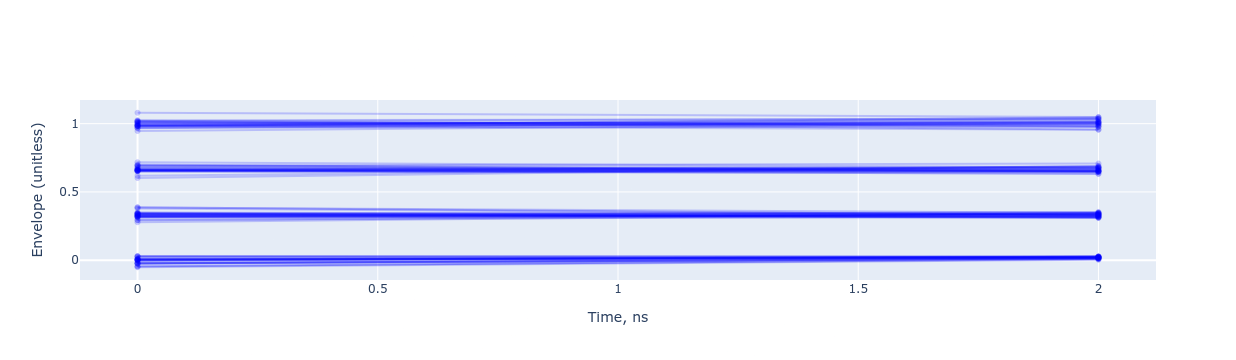

In [172]:
signal = system.find_child("receiver").output
fig = plot_eye_diagram(signal, symbol_rate=data_rate / bits_per_symbol, line={"color": "rgba(0, 0, 255, 0.2)"})
fig.show()

In [192]:
%time ber_tester(tf.constant(256), **system_params, ber_tester__n_iterations=tf.constant(10), ber_tester__batch_size=tf.constant(5000))

CPU times: user 24.7 s, sys: 11.8 s, total: 36.4 s
Wall time: 14.2 s


<tf.Tensor: shape=(), dtype=float32, numpy=0.023631796>

In [191]:
system.train_filter(2000, **system_params)

<tf.Tensor: shape=(), dtype=float32, numpy=0.0071541946>